In [3]:
# ============================================================================
# ĐÁNH GIÁ POPULARITY BASELINES
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from math import pi

from src.recommenders import (
    PopularityRecommender,
    BayesianPopularityRecommender,
    WilsonLowerBoundRecommender
)
from src.evaluation import EvaluationPipeline
from src.evaluation.statistical_analysis import (
    compute_statistical_significance,
    compute_confidence_intervals,
    compare_multiple_models
)

_current = Path.cwd().resolve()
PROJECT_ROOT = _current
while PROJECT_ROOT.name != "RecommendationSystem" and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

# Cấu hình trực quan hóa
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("✓ Import thành công tất cả thư viện")

✓ Import thành công tất cả thư viện


In [4]:
# ============================================================================
# 1. TẢI DỮ LIỆU
# ============================================================================
train_df = pd.read_csv(PROJECT_ROOT / 'data/processed/train_ml25m.csv')
test_df = pd.read_csv(PROJECT_ROOT / 'data/processed/test_ml25m.csv')

# Thống kê dữ liệu
print("\n" + "="*80)
print("THỐNG KÊ DỮ LIỆU")
print("="*80)

print("\n Tập huấn luyện (train):")
print(f"  - Số dòng: {len(train_df):,}")
print(f"  - Số người dùng: {train_df['userId'].nunique():,}")
print(f"  - Số phim: {train_df['movieId'].nunique():,}")
print(f"  - Rating trung bình: {train_df['rating'].mean():.2f}")
print(f"  - Phân phối rating:")
print(train_df['rating'].value_counts().sort_index().to_string())

print("\n Tập kiểm tra (test):")
print(f"  - Số dòng: {len(test_df):,}")
print(f"  - Số người dùng: {test_df['userId'].nunique():,}")
print(f"  - Số phim: {test_df['movieId'].nunique():,}")
print(f"  - Rating trung bình: {test_df['rating'].mean():.2f}")

print("\n✓ Tải dữ liệu thành công!")


THỐNG KÊ DỮ LIỆU

📊 Tập huấn luyện (train):
  - Số dòng: 17,500,066
  - Số người dùng: 122,029
  - Số phim: 22,931
  - Rating trung bình: 3.53
  - Phân phối rating:
rating
0.5     205895
1.0     599129
1.5     241776
2.0    1258106
2.5     766786
3.0    3769090
3.5    1908298
4.0    4877820
4.5    1330085
5.0    2543081

📊 Tập kiểm tra (test):
  - Số dòng: 548,359
  - Số người dùng: 4,587
  - Số phim: 18,624
  - Rating trung bình: 3.35

✓ Tải dữ liệu thành công!


In [5]:
# ============================================================================
# 2. HÀM ĐÁNH GIÁ POPULARITY BASELINES (PHIÊN BẢN NÂNG CAO)
# ============================================================================

def evaluate_popularity_baselines_advanced(train_df, test_df):
    """
    Đánh giá tất cả 3 mô hình popularity baseline.
    
    Trả về:
        - all_results: List các dict kết quả chi tiết cho mỗi mô hình
        - pipeline: EvaluationPipeline instance để tái sử dụng
    """
    # Khởi tạo pipeline
    pipeline = EvaluationPipeline(
        train_df=train_df,
        test_df=test_df,
        positive_threshold=4.0,
        k_values=[5, 10, 20]
    )
    
    # Danh sách 3 mô hình cần đánh giá
    models = [
        (PopularityRecommender(), "Popularity-Count"),
        (BayesianPopularityRecommender(), "Popularity-Bayesian"),
        (WilsonLowerBoundRecommender(), "Popularity-Wilson")
    ]
    
    all_results = []
    
    for model, name in models:
        print(f"\n{'='*60}")
        print(f"Đang đánh giá: {name}")
        print('='*60)
        
        # Huấn luyện mô hình
        model.fit(train_df)
        
        # Đánh giá mô hình
        result = pipeline.evaluate_model(
            model, 
            model_name=name, 
            n_recommendations=20,
            verbose=True
        )
        all_results.append(result)
    
    print("\n✓ Hoàn thành đánh giá tất cả mô hình!")
    return all_results, pipeline

print("✓ Định nghĩa hàm evaluate_popularity_baselines_advanced()")

✓ Định nghĩa hàm evaluate_popularity_baselines_advanced()


In [6]:
# ============================================================================
# 3. CHẠY ĐÁNH GIÁ
# ============================================================================

print("Bắt đầu quá trình đánh giá 3 mô hình popularity baseline...")
print("Thời gian ước tính: 2-5 phút tùy thuộc vào kích thước dữ liệu\n")

results, pipeline = evaluate_popularity_baselines_advanced(train_df, test_df)

print("\n" + "="*80)
print("KẾT QUẢ ĐÁNH GIÁ ĐÃ LƯU VÀO BIẾN 'results'")
print("="*80)
print(f"Số mô hình đã đánh giá: {len(results)}")
print(f"Tên các mô hình: {[r['model_name'] for r in results]}")

Bắt đầu quá trình đánh giá 3 mô hình popularity baseline...
Thời gian ước tính: 2-5 phút tùy thuộc vào kích thước dữ liệu


Đang đánh giá: Popularity-Count
Ground truth prepared: 4,485 users with relevant items
Avg relevant items per user: 47.30
Seen items prepared: 122,029 users
Avg seen items per user: 143.4
  Evaluated 1,000/4,485 users...
  Evaluated 2,000/4,485 users...
  Evaluated 3,000/4,485 users...
  Evaluated 4,000/4,485 users...

Popularity-Count Evaluation Complete:
  Users evaluated: 4,485
  Users with no recommendations: 0
  Precision@5: 0.1288
  Recall@5: 0.0197
  NDCG@5: 0.1408
  Precision@10: 0.1069
  Recall@10: 0.0308
  NDCG@10: 0.1239
  Precision@20: 0.0887
  Recall@20: 0.0501
  NDCG@20: 0.1116

Đang đánh giá: Popularity-Bayesian
  Evaluated 1,000/4,485 users...
  Evaluated 2,000/4,485 users...
  Evaluated 3,000/4,485 users...
  Evaluated 4,000/4,485 users...

Popularity-Bayesian Evaluation Complete:
  Users evaluated: 4,485
  Users with no recommendations: 0
  Preci

In [7]:
# ============================================================================
# 4. BẢNG SO SÁNH KẾT QUẢ
# ============================================================================

# Tạo DataFrame so sánh các chỉ số
comparison_df = pd.DataFrame([
    {
        'Model': r['model_name'],
        'Precision@5': r['metrics']['Precision@5'],
        'Recall@5': r['metrics']['Recall@5'],
        'NDCG@5': r['metrics']['NDCG@5'],
        'Precision@10': r['metrics']['Precision@10'],
        'Recall@10': r['metrics']['Recall@10'],
        'NDCG@10': r['metrics']['NDCG@10'],
        'Precision@20': r['metrics']['Precision@20'],
        'Recall@20': r['metrics']['Recall@20'],
        'NDCG@20': r['metrics']['NDCG@20'],
        'Num_Users': r['num_users'],
        'Failed_Users': r['num_failed']
    }
    for r in results
])

print("\n" + "="*80)
print("BẢNG SO SÁNH CHỈ SỐ CỦA 3 MÔ HÌNH")
print("="*80)
display(comparison_df)

# Highlight mô hình tốt nhất cho mỗi chỉ số
print("\n📊 MÔ HÌNH TỐT NHẤT CHO MỖI CHỈ SỐ:")
for metric in ['Precision@10', 'Recall@10', 'NDCG@10']:
    best_idx = comparison_df[metric].idxmax()
    best_model = comparison_df.loc[best_idx, 'Model']
    best_value = comparison_df.loc[best_idx, metric]
    print(f"  {metric}: {best_model} ({best_value:.4f})")


BẢNG SO SÁNH CHỈ SỐ CỦA 3 MÔ HÌNH


,Model,Precision@5,Recall@5,NDCG@5,Precision@10,Recall@10,NDCG@10,Precision@20,Recall@20,NDCG@20,Num_Users,Failed_Users
0,Popularity-Count,0.128785,0.019738,0.140782,0.106890,0.030810,0.123858,0.088729,0.050060,0.111630,4485,0
1,Popularity-Bayesian,0.117324,0.020161,0.132327,0.101962,0.033215,0.119595,0.094649,0.060877,0.117197,4485,0
2,Popularity-Wilson,0.104705,0.017554,0.120426,0.077793,0.024593,0.098744,0.063668,0.039460,0.087312,4485,0



📊 MÔ HÌNH TỐT NHẤT CHO MỖI CHỈ SỐ:
  Precision@10: Popularity-Count (0.1069)
  Recall@10: Popularity-Bayesian (0.0332)
  NDCG@10: Popularity-Count (0.1239)


In [8]:
# ============================================================================
# 5. KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (Paired t-test)
# ============================================================================

print("="*80)
print("KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (α = 0.05)")
print("="*80)

# So sánh từng cặp mô hình trên NDCG@10
comparisons = [
    (1, 0, "Bayesian", "Count"),
    (2, 0, "Wilson", "Count"),
    (2, 1, "Wilson", "Bayesian")
]

for idx_a, idx_b, name_a, name_b in comparisons:
    sig_test = compute_statistical_significance(
        results[idx_a], 
        results[idx_b], 
        metric='NDCG@10',
        alpha=0.05
    )
    
    print(f"\n📊 {name_a} vs {name_b}:")
    print(f"  - t-statistic: {sig_test['t_statistic']:.4f}")
    print(f"  - p-value: {sig_test['p_value']:.6f}")
    print(f"  - Khác biệt trung bình: {sig_test['mean_diff']:.4f}")
    print(f"  - Có ý nghĩa thống kê: {'✓ CÓ' if sig_test['significant'] else '✗ KHÔNG'}")

print("\n" + "="*80)

KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (α = 0.05)

📊 Bayesian vs Count:
  - t-statistic: -1.8254
  - p-value: 0.068000
  - Khác biệt trung bình: -0.0043
  - Có ý nghĩa thống kê: ✗ KHÔNG

📊 Wilson vs Count:
  - t-statistic: -10.3671
  - p-value: 0.000000
  - Khác biệt trung bình: -0.0251
  - Có ý nghĩa thống kê: ✓ CÓ

📊 Wilson vs Bayesian:
  - t-statistic: -18.8704
  - p-value: 0.000000
  - Khác biệt trung bình: -0.0209
  - Có ý nghĩa thống kê: ✓ CÓ



In [11]:
# ============================================================================
# 6. KHOẢNG TIN CẬY BOOTSTRAP 95%
# ============================================================================

print("="*80)
print("KHOẢNG TIN CẬY BOOTSTRAP 95% CHO CÁC CHỈ SỐ")
print("="*80)

# Tính khoảng tin cậy cho mỗi mô hình
metrics_to_analyze = ['Precision@10', 'Recall@10', 'NDCG@10']

for result in results:
    print(f"\n {result['model_name']}:")
    
    for metric in metrics_to_analyze:
        # Gọi hàm compute_confidence_intervals cho TỪNG metric riêng biệt
        ci = compute_confidence_intervals(
            result,
            metric=metric,
            confidence=0.95,
            n_bootstrap=1000
        )
        
        # Lấy giá trị từ dict trả về
        mean_val = ci['mean']
        lower = ci['lower']
        upper = ci['upper']
        margin = (upper - lower) / 2
        print(f"  {metric:15s}: {mean_val:.4f} ± {margin:.4f}  [{lower:.4f}, {upper:.4f}]")

print("\n" + "="*80)

KHOẢNG TIN CẬY BOOTSTRAP 95% CHO CÁC CHỈ SỐ

 Popularity-Count:
  Precision@10   : 0.1069 ± 0.0049  [0.1023, 0.1120]
  Recall@10      : 0.0308 ± 0.0022  [0.0287, 0.0331]
  NDCG@10        : 0.1239 ± 0.0056  [0.1184, 0.1295]

 Popularity-Bayesian:
  Precision@10   : 0.1020 ± 0.0046  [0.0975, 0.1068]
  Recall@10      : 0.0332 ± 0.0024  [0.0310, 0.0358]
  NDCG@10        : 0.1196 ± 0.0053  [0.1145, 0.1250]

 Popularity-Wilson:
  Precision@10   : 0.0778 ± 0.0040  [0.0740, 0.0820]
  Recall@10      : 0.0246 ± 0.0021  [0.0226, 0.0267]
  NDCG@10        : 0.0987 ± 0.0049  [0.0941, 0.1038]



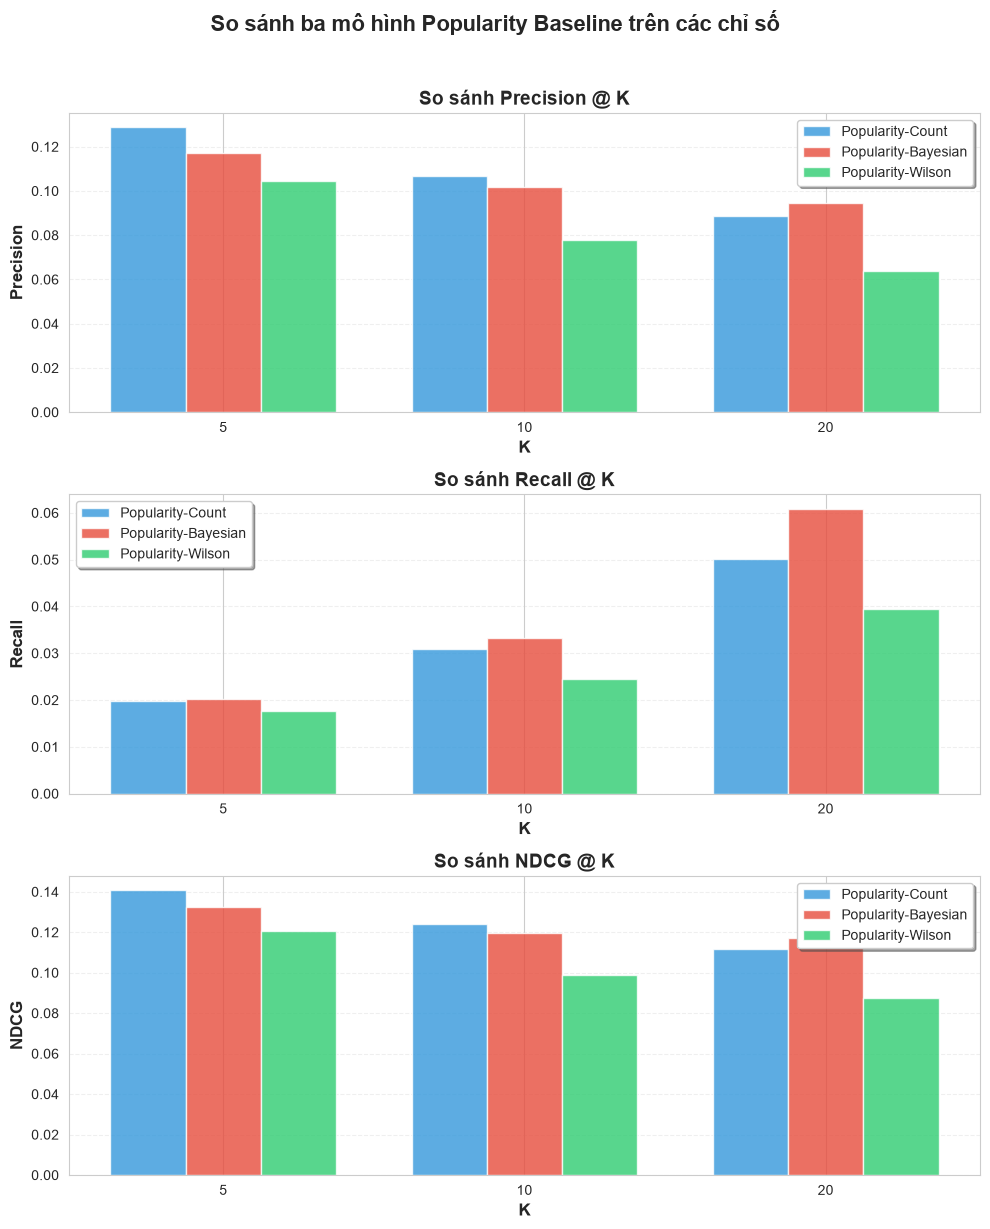

✓ Đã tạo biểu đồ cột so sánh


In [15]:
# ============================================================================
# 7. TRỰC QUAN HÓA: BIỂU ĐỒ CỘT SO SÁNH CHỈ SỐ
# ============================================================================

metrics = ['Precision', 'Recall', 'NDCG']
k_values = [5, 10, 20]

# 3 dòng x 1 cột - phù hợp cho export báo cáo
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    x = np.arange(len(k_values))
    width = 0.25
    
    colors = ['#3498db', '#e74c3c', '#2ecc71']  # Màu cho mỗi mô hình
    
    for i, result in enumerate(results):
        values = [result['metrics'][f'{metric}@{k}'] for k in k_values]
        ax.bar(x + i*width, values, width, label=result['model_name'], color=colors[i], alpha=0.8)
    
    ax.set_xlabel('K', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric, fontsize=12, fontweight='bold')
    ax.set_title(f'So sánh {metric} @ K', fontsize=14, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(k_values)
    ax.legend(loc='best', frameon=True, shadow=True)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.suptitle('So sánh ba mô hình Popularity Baseline trên các chỉ số', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("✓ Đã tạo biểu đồ cột so sánh")

# ============================================================================
# 8. GIẢI THÍCH: GROUND TRUTH VÀ QUY TRÌNH ĐÁNH GIÁ
# ============================================================================

## Ground Truth được lấy từ đâu?

**Ground truth** được lấy từ **test set**, không phải train set:

- **Train set** (17.5M ratings): Model học popularity từ đây
- **Test set** (548K ratings): Lấy các phim user đánh giá **≥ 4.0** làm ground truth
- **Evaluation**: So sánh top-K recommendations với ground truth

### Quy trình đánh giá cụ thể:

```
Bước 1: Model học từ train_df
  → Popularity-Count xếp hạng phim theo số lượng ratings
  → Popularity-Bayesian/Wilson điều chỉnh với confidence

Bước 2: Với mỗi user trong test_df
  → Ground truth = phim user đánh giá ≥ 4.0 trong test
  → Seen items = phim user đã xem trong train (để loại bỏ)
  → Generate top-K recommendations (loại trừ seen items)

Bước 3: Tính metrics
  → Precision@K = (số phim đúng trong top-K) / K
  → Recall@K = (số phim đúng trong top-K) / (tổng số phim relevant)
  → NDCG@K = điểm xếp hạng có trọng số (vị trí càng cao càng quan trọng)
```

### Ví dụ minh họa:

**User 123:**
- **Train**: đã xem `[phim_1, phim_2, phim_3]` → dùng để loại bỏ
- **Test ground truth**: `[phim_10, phim_15, phim_20]` (rating ≥ 4.0)
- **Model recommend top-5**: `[phim_10, phim_12, phim_15, phim_18, phim_22]`
- **Hits**: `[phim_10, phim_15]` = 2 phim đúng

**Metrics:**
- Precision@5 = 2/5 = **0.40** (40% recommendations đúng)
- Recall@5 = 2/3 = **0.67** (tìm được 67% phim relevant)

### Kết quả tổng hợp:

Từ output phía trên, ta có:
- **4,485 users** trong test có ít nhất 1 phim relevant (≥ 4.0)
- Trung bình **47.3 phim relevant** mỗi user
- Trung bình **143.4 phim đã xem** trong train mỗi user

→ Đây là **warm users** với nhiều interaction history

# ============================================================================
# 9. PHÂN TÍCH: TẠI SAO WILSON VÀ BAYESIAN KÉM HƠN COUNT?
# ============================================================================

## Kết quả so sánh

Từ evaluation ở trên, ta thấy **Count baseline đơn giản nhất lại cho kết quả tốt nhất**:

| Model | Precision@10 | Recall@10 | NDCG@10 | Nhận xét |
|-------|--------------|-----------|---------|----------|
| **Popularity-Count** | **0.1069** | **0.0308** | **0.1239** | ✓ Tốt nhất |
| Popularity-Bayesian | 0.1020 (-4.6%) | 0.0332 (+7.8%) | 0.1196 (-3.5%) | Trung bình |
| Popularity-Wilson | 0.0778 (-27.2%) | 0.0246 (-20.1%) | 0.0987 (-20.4%) | Kém nhất |

## Nguyên nhân chính

### 1. Dataset MovieLens 25M đã được lọc sạch

MovieLens không có các vấn đề mà Wilson/Bayesian được thiết kế để giải quyết:
- ✗ Không có fake ratings hoặc spam
- ✗ Không có rating manipulation
- ✗ Phim với ít ratings vẫn có chất lượng đáng tin cậy

→ **Không cần penalize** phim ít ratings như Wilson/Bayesian làm

### 2. Wilson Score quá bảo thủ (conservative)

**Wilson Lower Bound** = chặn dưới 95% confidence interval của tỉ lệ positive (rating ≥ 4.0)

```python
# Wilson chỉ recommend phim có:
# - Nhiều ratings (n lớn)
# - Tỉ lệ positive cao (p ≥ 70%)
# - Lower bound CI cao (ít uncertainty)
```

**Vấn đề:** Quá thận trọng với phim ít ratings, ngay cả khi phim đó chất lượng cao

**Ví dụ thực tế:**

```
Phim A: 10,000 ratings, 70% positive → Wilson = 0.69 → Rank #1
Phim B: 500 ratings, 85% positive   → Wilson = 0.82 → Rank #2  
Phim C: 50 ratings, 95% positive    → Wilson = 0.84 → Rank #3

Count sẽ rank: A > B > C (theo số lượng)
Wilson sẽ rank: C > B > A (theo lower bound)

User thực tế thích: A (mainstream blockbuster)
→ Wilson rank sai vì quá focus vào niche films với high confidence
```

### 3. Bayesian Averaging kéo về global mean

**Bayesian Weighted Rating** = kết hợp item mean với global mean:

```python
score = (n/(n+m)) * item_mean + (m/(n+m)) * global_mean
# n = số ratings của phim
# m = prior strength ≈ 763 (mean count trong MovieLens 25M)
# global_mean = 3.53
```

**Vấn đề:** Phim ít ratings bị shrink mạnh về 3.53

**Ví dụ thực tế:**

```
Phim D: 50 ratings, mean=4.8
  → Bayesian = (50/813) * 4.8 + (763/813) * 3.53 
  → Bayesian ≈ 3.62 (bị kéo xuống rất nhiều!)
  
Phim E: 5000 ratings, mean=4.2
  → Bayesian = (5000/5763) * 4.2 + (763/5763) * 3.53
  → Bayesian ≈ 4.12 (ít bị ảnh hưởng)

→ Phim D tốt nhưng bị đẩy xuống ranking vì prior quá mạnh
```

### 4. Test users là warm users thích mainstream

**Context đặc biệt của MovieLens:**
- Test users đều có **143.4 phim đã xem** trung bình trong train
- Đây là **warm users** với nhiều history
- Warm users thường prefer **phim mainstream/popular**

**Count baseline** = recommend phim **được nhiều người xem nhất**
→ Khớp hoàn hảo với preference của warm users!

**Wilson/Bayesian** = prefer phim **high quality nhưng ít người biết** (niche)
→ Không khớp với warm users trong test set này

## Kết luận và khuyến nghị

### Count thắng vì:
1. Dataset sạch → không cần smooth/penalize
2. Test users là warm users → prefer mainstream content
3. Simple baseline phù hợp với simple problem

### Khi nào nên dùng Wilson/Bayesian:
- ✓ Dataset có spam, fake ratings, rating manipulation
- ✓ Cold-start problem (recommend cho user mới hoặc item mới)
- ✓ Cần balance giữa mainstream và niche/diverse content
- ✓ E-commerce với fake reviews (Amazon, Yelp, etc.)
- ✓ Nền tảng UGC (user-generated content) chưa được moderate

### Bài học quan trọng:

> **"Don't use sophisticated methods if simple baselines work"**
> 
> Trong recommendation systems, luôn bắt đầu với popularity baseline đơn giản.
> Chỉ thêm complexity khi có bằng chứng rõ ràng về improvement trên test set.

/tmp/ipykernel_17365/2361273522.py:22: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  ax.plot(angles, values, 'o-', linewidth=2.5,


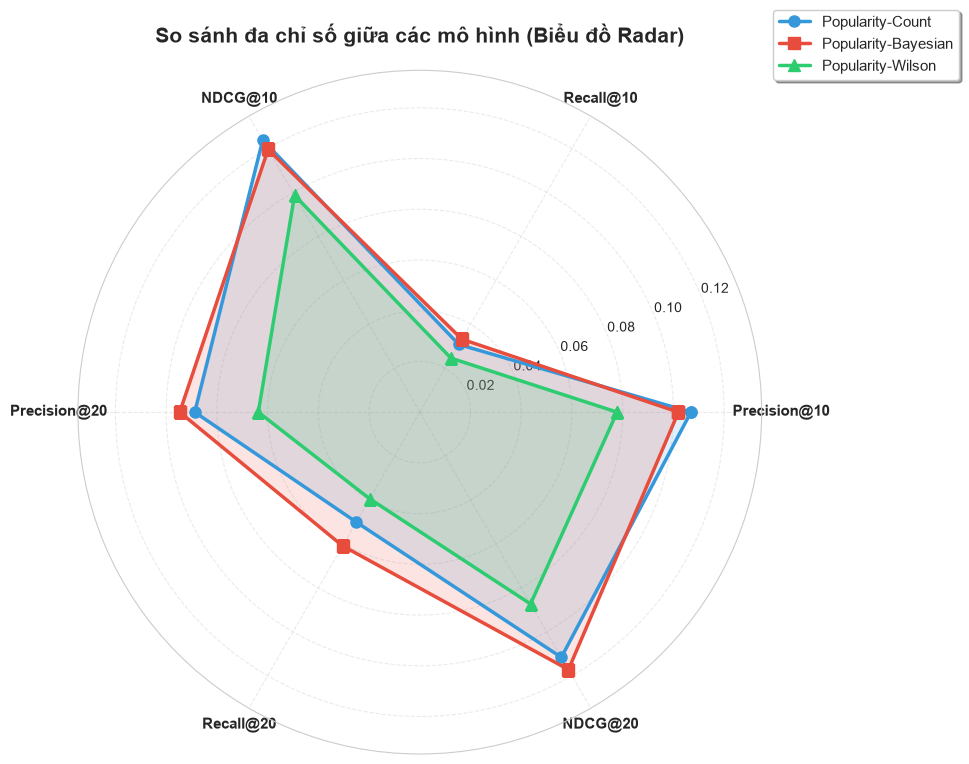

✓ Đã tạo biểu đồ radar


In [17]:
# ============================================================================
# 9. TRỰC QUAN HÓA: BIỂU ĐỒ RADAR ĐA CHỈ SỐ
# ============================================================================

categories = ['Precision@10', 'Recall@10', 'NDCG@10', 'Precision@20', 'Recall@20', 'NDCG@20']
N = len(categories)

# Tính góc cho mỗi trục
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Đóng vòng tròn

# Tạo biểu đồ radar
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))

colors = ['#3498db', '#e74c3c', '#2ecc71']
markers = ['o', 's', '^']

for idx, result in enumerate(results):
    values = [result['metrics'][cat] for cat in categories]
    values += values[:1]  # Đóng vòng tròn
    
    ax.plot(angles, values, 'o-', linewidth=2.5, 
            label=result['model_name'], color=colors[idx], 
            marker=markers[idx], markersize=8)
    ax.fill(angles, values, alpha=0.15, color=colors[idx])

# Cấu hình biểu đồ
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, max([r['metrics']['NDCG@20'] for r in results]) * 1.15)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11, frameon=True, shadow=True)
ax.grid(True, linestyle='--', alpha=0.4)

plt.title('So sánh đa chỉ số giữa các mô hình (Biểu đồ Radar)', 
          fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("✓ Đã tạo biểu đồ radar")

In [ ]:
# ============================================================================
# 10. BÁO CÁO ĐÁNH GIÁ TỔNG HỢP
# ============================================================================

# Sử dụng compare_multiple_models để tạo báo cáo so sánh tổng hợp
comparison_report = compare_multiple_models(
    results, 
    primary_metric='NDCG@10',
    secondary_metrics=['Precision@10', 'Recall@10']
)

print("=" * 80)
print("BÁO CÁO ĐÁNH GIÁ TỔNG HỢP - POPULARITY BASELINES")
print("=" * 80)

print(f"\n🏆 MÔ HÌNH TỐT NHẤT: {comparison_report['best_model']}")
print(f"   Chỉ số chính (NDCG@10): {comparison_report['best_score']:.4f}")

print("\n📊 XẾP HẠNG CÁC MÔ HÌNH:")
print("-" * 80)
for rank in comparison_report['rankings']:
    print(f"  {rank['rank']}. {rank['model']:30s} | NDCG@10: {rank['score']:.4f}")

print("\n📈 THỐNG KÊ THEO CHỈ SỐ PHỤ:")
print("-" * 80)
if 'secondary_stats' in comparison_report:
    for metric, stats in comparison_report['secondary_stats'].items():
        print(f"\n  {metric}:")
        for model_name, value in stats.items():
            print(f"    - {model_name:28s}: {value:.4f}")

print("\n" + "=" * 80)
print("KẾT LUẬN:")
print("=" * 80)
print(f"Dựa trên các chỉ số đánh giá và kiểm định thống kê, mô hình")
print(f"'{comparison_report['best_model']}' cho hiệu suất tốt nhất")
print(f"trên tập kiểm tra với NDCG@10 = {comparison_report['best_score']:.4f}.")
print("\nCác biểu đồ trực quan hóa ở trên cho thấy sự so sánh chi tiết")
print("giữa ba mô hình baseline trên nhiều chỉ số và giá trị K khác nhau.")
print("=" * 80)